# Proyecto final — Modelos y Simulación II

**Universidad de Antioquia · Facultad de Ingeniería**

- **Equipo:** Samuel Puerta Patiño, Simón Berrio Gaviria, Juan Estiven Carmona Muñoz
- **Grupo:** 5 · **Semestre:** 2026-2 · **Dataset:** *Financial Transactions & Fraud Detection* (Kaggle)

## Sección 5: análisis de variables y reducción de dimensión

La sección 4 mostró que, con las 37 columnas del conjunto D (variables originales, de caracterización y `risk_score`), los modelos sensibles al ruido rinden menos que con el conjunto C, y que los modelos de árboles igualan a `risk_score` usado solo. Esta sección responde a la guía en tres pasos, con los **dos mejores modelos de la sección 4: Random Forest balanceado y gradient boosting ponderado** (los de mayor PR-AUC puntual; según los notebooks 03 y 04 son estadísticamente equivalentes entre sí y con `risk_score` usado solo).

| Apartado | Contenido | Ítem de la guía |
|---|---|---|
| 5.1 | Análisis individual de variables y criterio de eliminación | 9 |
| 5.2 | Referencia (espacio completo) y reducción por selección de variables (dos versiones) | 9 |
| 5.3 | PCA con reajuste de hiperparámetros | 10 |
| 5.4 | UMAP con reajuste de hiperparámetros | 11 |
| 5.5 | Comparación de los espacios y tabla final con el porcentaje de reducción | 10 y 11 |
| 5.6 | Conclusiones de la sección (la discusión general y el modelo final están en el notebook 07) | 12 |

**Protocolo (el mismo del notebook 03).**
- Partición de prueba del 20 % con `random_state = 42` y validación cruzada estratificada de 5 particiones repetida 2 veces sobre el 80 % de entrenamiento. La prueba se usa **una sola vez**, al final, para evaluar el modelo ya ajustado en cada espacio.
- En cada espacio se **reajustan los hiperparámetros del modelo** (y los de la reducción: el número de componentes de PCA y la dimensión de UMAP) con una búsqueda en malla que optimiza la PR-AUC. La reducción de dimensión **se ajusta dentro de cada partición de entrenamiento** (forma parte del *pipeline*) y se aplica a la partición de validación con `transform`: nunca se ajusta con datos de validación ni de prueba.
- Los intervalos de la validación cruzada usan la corrección de Nadeau y Bengio (como en el notebook 04); los de la prueba, bootstrap estratificado. Las diferencias entre espacios se contrastan con una prueba t pareada con esa corrección, sobre las mismas particiones.
- **Mallas de hiperparámetros.** Son la del notebook 03 para estos dos modelos, con una reducción de costo: el Random Forest balanceado usa 200 árboles (no 500) y `min_samples_leaf` ∈ {5, 20}. La misma malla se usa en todos los espacios, para que las diferencias no dependan del ajuste.
- Como el número de componentes o la dimensión de UMAP se elige por validación cruzada, la PR-AUC de validación de PCA y UMAP está algo inflada por esa selección. Esto **favorece** a PCA y UMAP; por tanto, si aun así no superan al espacio completo, la conclusión se mantiene a fortiori.

> **Ejecución.** Requiere `data/caracteristicas.csv` (lo genera el notebook 01) y `umap-learn`. Ejecutar desde la carpeta `notebooks/`. La ejecución completa toma del orden de una hora en un solo núcleo; las búsquedas usan `N_JOBS` procesos (celda de configuración), que conviene ajustar según la máquina.

In [1]:
from pathlib import Path
from tempfile import gettempdir
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from imblearn.ensemble import BalancedRandomForestClassifier
from joblib import Memory
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, make_scorer, roc_auc_score
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_PART, N_REP = 5, 2
N_ARBOLES = 200
REPLICAS_BOOTSTRAP = 2000
PERMUTACIONES = 5000
N_JOBS = 6

DATA_PATH = Path("../data/caracteristicas.csv")
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cd0"]
COLOR_REF = "#52514e"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

c:\Users\Admin\Documents\Modelos II\Proyecto Final\FinancialTransactions-FraudDetection-Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
y = df["is_fraud"].to_numpy()

ORIG_NUM = ["amount_log", "hour_sin", "hour_cos"]
ORIG_BIN = ["is_weekend"]
CAT = ["account_type", "category", "payment_method", "device_type"]
CARACT_CONT = ["transacciones_previas", "horas_desde_anterior_log", "desvio_log_monto",
               "transacciones_24h", "transacciones_7d", "monto_7d_log", "anomalia_historial"]
CARACT_BIN = ["primera_transaccion", "cambio_dispositivo", "cambio_metodo_pago",
              "cambio_categoria", "dispositivo_nuevo", "cuenta_pago_incoherente"]
CONT = ORIG_NUM + CARACT_CONT + ["risk_score"]
BIN = ORIG_BIN + CARACT_BIN
COLS = CONT + BIN + CAT
GRUPO = {**{v: "Original" for v in ORIG_NUM + ORIG_BIN + CAT}, **{v: "Historial" for v in CARACT_CONT + CARACT_BIN},
         "risk_score": "risk_score"}

X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
CV = RepeatedStratifiedKFold(n_splits=N_PART, n_repeats=N_REP, random_state=RANDOM_STATE)
K = CV.get_n_splits()
R_NB = 1 / (N_PART - 1)

FRACCION_ALERTAS = 0.02


def _top(y_true, s):
    k = int(np.ceil(FRACCION_ALERTAS * len(y_true)))
    return np.asarray(y_true)[np.argsort(-np.asarray(s), kind="stable")[:k]]


def recall_top(y_true, s):
    return _top(y_true, s).sum() / np.sum(y_true)


def precision_top(y_true, s):
    return _top(y_true, s).mean()


RESPUESTA = ("decision_function", "predict_proba")
METRICAS = {"pr_auc": make_scorer(average_precision_score, response_method=RESPUESTA),
            "roc_auc": make_scorer(roc_auc_score, response_method=RESPUESTA),
            "recall_2pct": make_scorer(recall_top, response_method=RESPUESTA),
            "precision_2pct": make_scorer(precision_top, response_method=RESPUESTA)}
FUNCIONES = {"pr_auc": average_precision_score, "roc_auc": roc_auc_score,
             "recall_2pct": recall_top, "precision_2pct": precision_top}


def ic_nb(v, r=R_NB, conf=0.95):
    """IC con la corrección de Nadeau y Bengio (varianza s^2 (1/k + n_prueba/n_entrenamiento))."""
    v = np.asarray(v, dtype=float)
    k = len(v)
    h = stats.t.ppf((1 + conf) / 2, k - 1) * np.sqrt(v.var(ddof=1) * (1 / k + r))
    return v.mean(), v.mean() - h, v.mean() + h


def fmt_nb(v):
    m, lo, hi = ic_nb(v)
    return f"{m:.3f} [{lo:.3f}, {hi:.3f}]"


def prueba_pareada_nb(a, b, r=R_NB):
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    k = len(d)
    var = d.var(ddof=1) * (1 / k + r)
    if var <= 0:
        return d.mean(), np.nan
    t = d.mean() / np.sqrt(var)
    return d.mean(), 2 * stats.t.sf(abs(t), k - 1)


def bootstrap_ic(y_true, s, funcion, replicas=REPLICAS_BOOTSTRAP, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    pos, neg = np.flatnonzero(y_true == 1), np.flatnonzero(y_true == 0)
    v = [funcion(y_true[i], s[i]) for i in
         (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(replicas))]
    return np.percentile(v, [2.5, 97.5])


def benjamini_hochberg(p):
    p = np.asarray(p, dtype=float)
    m = len(p)
    orden = np.argsort(p)
    ajustado = np.minimum.accumulate((p[orden] * m / np.arange(1, m + 1))[::-1])[::-1]
    q = np.empty(m)
    q[orden] = np.minimum(ajustado, 1)
    return q


print(f"Entrenamiento: {len(y_train):,} transacciones, {y_train.sum()} fraudes · Prueba: {len(y_test):,} transacciones, {y_test.sum()} fraudes")
print(f"Validación cruzada: {N_PART} particiones × {N_REP} repeticiones = {K} evaluaciones · variables: {len(COLS)} (37 columnas tras la codificación)")

Entrenamiento: 8,000 transacciones, 101 fraudes · Prueba: 2,000 transacciones, 25 fraudes
Validación cruzada: 5 particiones × 2 repeticiones = 10 evaluaciones · variables: 22 (37 columnas tras la codificación)


## 5.1 Análisis individual de variables (ítem 9)

Cada una de las 22 variables se contrasta **por separado** con la etiqueta, usando solo el conjunto de entrenamiento (así la decisión de eliminar variables no usa información de la partición de prueba):

- **Variables continuas y binarias:** área bajo la curva ROC univariada (AUC; 0,5 = sin relación) con intervalo bootstrap del 95 %, y prueba de Mann-Whitney. Los faltantes de la fase de caracterización se imputan con la mediana, como en el *pipeline*.
- **Variables categóricas:** V de Cramér y p-valor de una prueba de permutación sobre el estadístico χ² (se permuta la etiqueta 5000 veces), porque varios niveles tienen menos de 5 fraudes esperados.
- **Multiplicidad:** con 22 pruebas se corrige con Benjamini–Hochberg (tasa de falsos descubrimientos del 5 %), y se reporta también la comparación con el umbral de Bonferroni.

**Criterio de eliminación (fijado antes de ver los resultados):** una variable se **conserva** solo si su q-valor de Benjamini–Hochberg es menor que 0,05. Como un análisis individual no ve interacciones, se **complementa** con la importancia por permutación de los dos mejores modelos (más abajo): una variable sin efecto individual pero con importancia en los modelos habría que conservarla.

In [3]:
def auc_con_ic(yv, x, replicas=REPLICAS_BOOTSTRAP // 2, semilla=RANDOM_STATE):
    rng = np.random.default_rng(semilla)
    pos, neg = np.flatnonzero(yv == 1), np.flatnonzero(yv == 0)
    v = [roc_auc_score(yv[i], x[i]) for i in
         (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(replicas))]
    return roc_auc_score(yv, x), np.percentile(v, 2.5), np.percentile(v, 97.5)


def chi2_por_nivel(codigos, yv, n_niveles):
    n1 = np.bincount(codigos, weights=yv, minlength=n_niveles)
    n = np.bincount(codigos, minlength=n_niveles).astype(float)
    esp1 = n * yv.mean()
    esp0 = n * (1 - yv.mean())
    return np.sum((n1 - esp1) ** 2 / esp1) + np.sum(((n - n1) - esp0) ** 2 / esp0)


def cramer_permutacion(serie, yv, permutaciones=PERMUTACIONES, semilla=RANDOM_STATE):
    codigos, niveles = pd.factorize(serie)
    k = len(niveles)
    obs = chi2_por_nivel(codigos, yv, k)
    rng = np.random.default_rng(semilla)
    nulo = np.array([chi2_por_nivel(codigos, rng.permutation(yv), k) for _ in range(permutaciones)])
    p = (1 + np.sum(nulo >= obs)) / (permutaciones + 1)
    v = lambda c2: np.sqrt(c2 / len(yv))
    return v(obs), p, np.percentile(v(nulo), 95)


filas = []
for var in CONT + BIN:
    x = X_train[var].fillna(X_train[var].median()).to_numpy(float)
    a, lo, hi = auc_con_ic(y_train, x)
    p = stats.mannwhitneyu(x[y_train == 1], x[y_train == 0], alternative="two-sided").pvalue
    filas.append({"variable": var, "grupo": GRUPO[var], "tipo": "Binaria" if var in BIN else "Continua",
                  "estadístico": "AUC", "valor": a, "ref_inf": lo, "ref_sup": hi, "p": p})
for var in CAT:
    v, p, nulo95 = cramer_permutacion(X_train[var], y_train)
    filas.append({"variable": var, "grupo": GRUPO[var], "tipo": "Categórica", "estadístico": "V de Cramér",
                  "valor": v, "ref_inf": np.nan, "ref_sup": nulo95, "p": p})
indiv = pd.DataFrame(filas)
indiv["q (BH)"] = benjamini_hochberg(indiv["p"])
indiv["conservar"] = indiv["q (BH)"] < 0.05
indiv["supera Bonferroni"] = indiv["p"] < 0.05 / len(indiv)
indiv = indiv.sort_values("p").reset_index(drop=True)

mostrar = indiv[["variable", "grupo", "tipo", "estadístico", "valor", "p", "q (BH)", "conservar", "supera Bonferroni"]]
display(mostrar.style.format({"valor": "{:.3f}", "p": "{:.4f}", "q (BH)": "{:.3f}"}))
print(f"\nVariables conservadas según el criterio (q < 0,05): {indiv.loc[indiv['conservar'], 'variable'].tolist()}")
print(f"Variables eliminadas: {int((~indiv['conservar']).sum())} de {len(indiv)}")

,variable,grupo,tipo,estadístico,valor,p,q (BH),conservar,supera Bonferroni
0,risk_score,risk_score,Continua,AUC,0.633,0.0000,0.000,True,True
1,cambio_categoria,Historial,Binaria,AUC,0.448,0.0015,0.017,True,True
2,hour_sin,Original,Continua,AUC,0.436,0.0261,0.169,False,False
3,desvio_log_monto,Historial,Continua,AUC,0.562,0.0307,0.169,False,False
4,cuenta_pago_incoherente,Historial,Binaria,AUC,0.532,0.1071,0.471,False,False
5,anomalia_historial,Historial,Continua,AUC,0.462,0.1869,0.610,False,False
6,dispositivo_nuevo,Historial,Binaria,AUC,0.471,0.1940,0.610,False,False
7,is_weekend,Original,Binaria,AUC,0.525,0.2819,0.775,False,False
8,horas_desde_anterior_log,Historial,Continua,AUC,0.476,0.4048,0.859,False,False
9,cambio_dispositivo,Historial,Binaria,AUC,0.518,0.4403,0.859,False,False



Variables conservadas según el criterio (q < 0,05): ['risk_score', 'cambio_categoria']
Variables eliminadas: 20 de 22


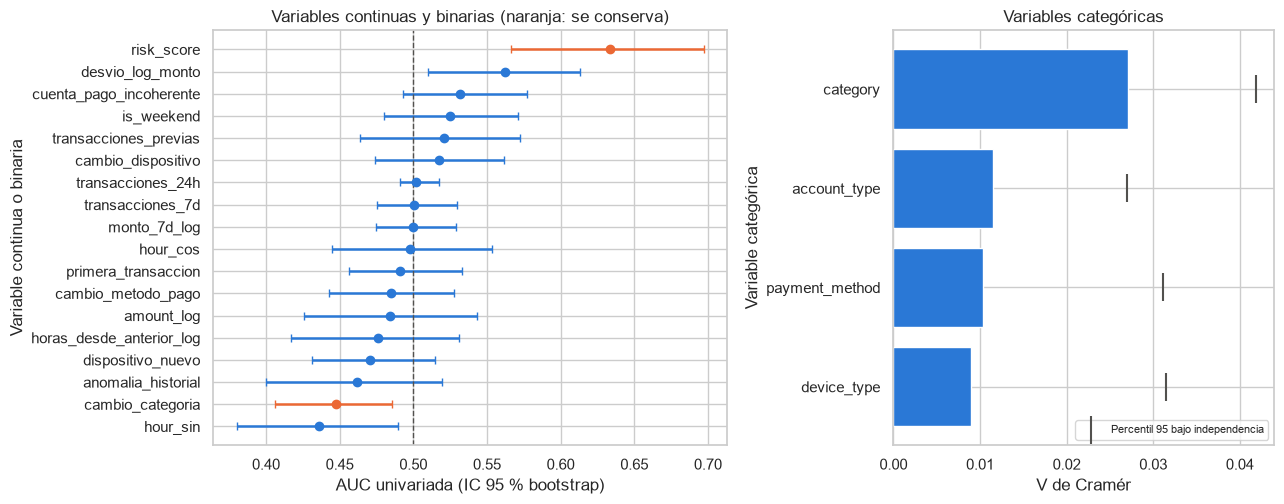

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})
num = indiv[indiv["estadístico"] == "AUC"].sort_values("valor")
ax = axes[0]
for j, (_, r) in enumerate(num.iterrows()):
    color = COLORES[1] if r["conservar"] else COLORES[0]
    ax.errorbar(r["valor"], j, xerr=[[r["valor"] - r["ref_inf"]], [r["ref_sup"] - r["valor"]]], fmt="o", ms=6, lw=1.8,
                capsize=3, color=color)
ax.axvline(0.5, color=COLOR_REF, ls="--", lw=1)
ax.set_yticks(range(len(num)), num["variable"])
ax.set_xlabel("AUC univariada (IC 95 % bootstrap)")
ax.set_ylabel("Variable continua o binaria")
ax.set_title("Variables continuas y binarias (naranja: se conserva)")

cat = indiv[indiv["estadístico"] == "V de Cramér"].sort_values("valor")
ax = axes[1]
ax.barh(range(len(cat)), cat["valor"], color=[COLORES[1] if c else COLORES[0] for c in cat["conservar"]])
ax.scatter(cat["ref_sup"], range(len(cat)), marker="|", s=400, color=COLOR_REF, label="Percentil 95 bajo independencia")
ax.set_yticks(range(len(cat)), cat["variable"])
ax.set_xlabel("V de Cramér")
ax.set_ylabel("Variable categórica")
ax.set_title("Variables categóricas")
ax.legend(fontsize=8, loc="lower right")
savefig("fig_analisis_individual")
plt.show()

*Figura (análisis individual). Izquierda: AUC univariada de las variables continuas y binarias con su intervalo bootstrap del 95 %; la línea discontinua es la ausencia de relación (0,5). Derecha: V de Cramér de las variables categóricas; la marca gris es el percentil 95 que se obtiene si la etiqueta fuera independiente. En naranja, las variables que superan el criterio de conservación.*

### Importancia por permutación de los dos mejores modelos

El análisis individual no detecta efectos que solo aparecen en combinación con otras variables. Para revisarlo, se ajusta cada modelo (hiperparámetros fijos razonables) en cada partición de entrenamiento y, en la partición de validación, se **permuta una variable a la vez** (la columna original, antes de la codificación) y se mide cuánto cae la PR-AUC. Una caída cercana a cero significa que el modelo no usa esa variable.

In [5]:
def preprocesador():
    return ColumnTransformer([
        ("cont", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), CONT),
        ("bin", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()), BIN),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])


def estimador(nombre):
    if nombre == "Random Forest balanceado":
        return BalancedRandomForestClassifier(n_estimators=N_ARBOLES, sampling_strategy="majority", replacement=False,
                                              bootstrap=False, random_state=RANDOM_STATE, n_jobs=1)
    return HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", early_stopping=False,
                                          random_state=RANDOM_STATE)


MODELOS = ["Random Forest balanceado", "Gradient boosting"]
FIJOS = {"Random Forest balanceado": dict(min_samples_leaf=20, max_features="sqrt"),
         "Gradient boosting": dict(learning_rate=0.03, max_depth=2)}

rng = np.random.default_rng(RANDOM_STATE)
filas = []
inicio = time.time()
splits = list(CV.split(X_train, y_train))[:10]
for nombre in MODELOS:
    for i, (tr, va) in enumerate(splits):
        m = Pipeline([("pre", preprocesador()), ("modelo", estimador(nombre).set_params(**FIJOS[nombre]))])
        m.fit(X_train.iloc[tr][COLS], y_train[tr])
        Xv, yv = X_train.iloc[va][COLS].copy(), y_train[va]
        base = average_precision_score(yv, m.predict_proba(Xv)[:, 1])
        for var in COLS:
            caidas = []
            for _ in range(2):
                Xp = Xv.copy()
                Xp[var] = rng.permutation(Xp[var].to_numpy())
                caidas.append(base - average_precision_score(yv, m.predict_proba(Xp)[:, 1]))
            filas.append({"modelo": nombre, "particion": i, "variable": var, "caida": np.mean(caidas)})
    print(f"{nombre}: listo ({time.time() - inicio:.0f} s acumulados)")
imp = pd.DataFrame(filas)

Random Forest balanceado: listo (28 s acumulados)
Gradient boosting: listo (49 s acumulados)


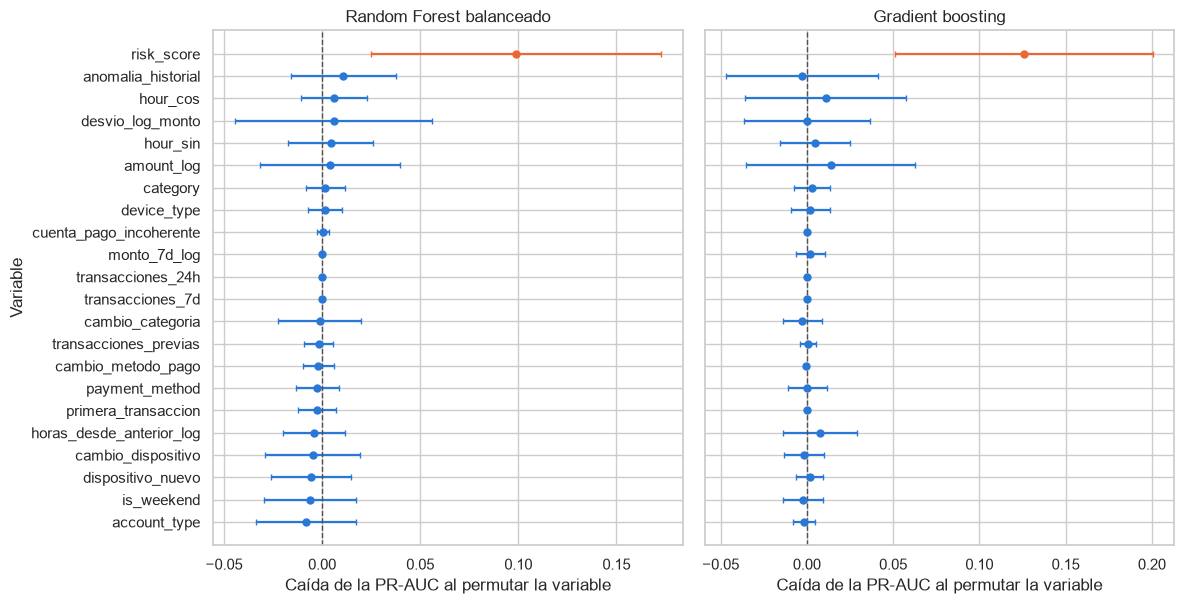

Variables cuya caída de PR-AUC tiene un IC 95 % que excluye el cero:
  Random Forest balanceado: ['risk_score']
  Gradient boosting: ['risk_score']


In [6]:
r_imp = 1 / (N_PART - 1)
resumen_imp = (imp.groupby(["modelo", "variable"])["caida"]
               .apply(lambda v: pd.Series(dict(zip(["media", "inf", "sup"], ic_nb(v, r_imp))))).unstack())
orden_vars = resumen_imp.xs("Random Forest balanceado")["media"].sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), sharey=True)
for ax, nombre in zip(axes, MODELOS):
    t = resumen_imp.xs(nombre).loc[orden_vars]
    for j, (var, r) in enumerate(t.iterrows()):
        color = COLORES[1] if var == "risk_score" else COLORES[0]
        ax.errorbar(r["media"], j, xerr=[[r["media"] - r["inf"]], [r["sup"] - r["media"]]], fmt="o", ms=5, lw=1.6, capsize=2.5, color=color)
    ax.axvline(0, color=COLOR_REF, ls="--", lw=1)
    ax.set_yticks(range(len(orden_vars)), orden_vars)
    ax.set_xlabel("Caída de la PR-AUC al permutar la variable")
    ax.set_title(nombre)
axes[0].set_ylabel("Variable")
savefig("fig_importancia_permutacion")
plt.show()

con_efecto = {nombre: resumen_imp.xs(nombre)[resumen_imp.xs(nombre)["inf"] > 0].index.tolist() for nombre in MODELOS}
print("Variables cuya caída de PR-AUC tiene un IC 95 % que excluye el cero:")
for nombre, v in con_efecto.items():
    print(f"  {nombre}: {v}")

*Figura (importancia por permutación). Caída media de la PR-AUC (intervalo del 95 % con corrección de Nadeau y Bengio) al permutar cada variable en la partición de validación. Solo `risk_score` (naranja) tiene una caída apreciable.*

### Decisión sobre las variables

El criterio (q < 0,05 en el análisis individual) se contrasta con las dos pruebas: solo se conservan las variables que superan el criterio. Las demás se eliminan **y** el resultado se verifica con los modelos: una variable eliminada que mostrara importancia por permutación obligaría a revisarlo. La reducción por selección que se evalúa en 5.2 aplica este mismo criterio de forma automática *dentro de cada partición de entrenamiento*, para que la selección no use la validación.

## 5.2 Espacio completo y reducción por selección de variables

Se definen aquí los *pipelines* y la búsqueda de hiperparámetros que se reutilizan para todos los espacios. Los dos primeros espacios son:

1. **Completo (D):** las 37 columnas del notebook 03. Es la referencia.
2. **Selección univariada (dentro de la validación):** tras el preprocesamiento, un filtro que ajusta, **solo con los datos de entrenamiento de cada partición**, una prueba de Mann-Whitney sobre cada columna codificada y conserva las que tienen q < 0,05 (Benjamini–Hochberg). Es el criterio del apartado 5.1 convertido en un paso del *pipeline*, pero a nivel de **columna codificada** (37 pruebas en lugar de 22, y con el 80 % de los datos de cada partición), por lo que es más estricto; si ninguna columna lo cumpliera, conserva la de menor p. Es la versión **sin fuga**.
3. **Variables del análisis 5.1:** exactamente las variables que superaron el criterio en 5.1, decididas con todo el conjunto de entrenamiento. Es la versión que corresponde literalmente a la decisión del apartado 5.1, pero como la decisión usa el mismo conjunto de entrenamiento que luego se valida, su validación es algo optimista; se incluye para ver qué aporta cada variable que el criterio conserva y la selección univariada no.

In [7]:
class SelectorUnivariado(BaseEstimator, TransformerMixin):
    """Conserva las columnas con q-valor (Benjamini–Hochberg) < q en una prueba de Mann-Whitney contra la etiqueta."""

    def __init__(self, q=0.05):
        self.q = q

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        p = np.nan_to_num(stats.mannwhitneyu(X[y == 1], X[y == 0], axis=0, method="asymptotic").pvalue, nan=1.0)
        self.p_ = p
        self.q_ = benjamini_hochberg(p)
        mascara = self.q_ < self.q
        if not mascara.any():
            mascara[np.argmin(p)] = True
        self.mascara_ = mascara
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.mascara_]


class ColumnasFijas(BaseEstimator, TransformerMixin):
    """Conserva columnas ya decididas (por índice) tras el preprocesamiento."""

    def __init__(self, indices=None):
        self.indices = indices

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.indices]


class UMAPEmbedding(BaseEstimator, TransformerMixin):
    """UMAP como paso de un pipeline: se ajusta con el entrenamiento y proyecta la validación con `transform`."""

    def __init__(self, n_components=2, n_neighbors=30, min_dist=0.1, supervisado=False, random_state=RANDOM_STATE):
        self.n_components = n_components
        self.n_neighbors = n_neighbors
        self.min_dist = min_dist
        self.supervisado = supervisado
        self.random_state = random_state

    def fit(self, X, y=None):
        self.umap_ = umap.UMAP(n_components=self.n_components, n_neighbors=self.n_neighbors, min_dist=self.min_dist,
                               random_state=self.random_state, n_jobs=1)
        self.umap_.fit(np.asarray(X, dtype=float), y if self.supervisado else None)
        return self

    def transform(self, X):
        return self.umap_.transform(np.asarray(X, dtype=float))


MEMORIA = Memory(location=Path(gettempdir()) / "cache_nb05_proyecto_fraude", verbose=0)
N_VECINOS = 30
K_PCA = [2, 5, 10, 20, 30]
D_UMAP = [2, 5, 10]
D_UMAP_SUP = [2, 5]

MALLA_MODELO = {
    "Random Forest balanceado": {"modelo__min_samples_leaf": [5, 20], "modelo__max_features": ["sqrt", 0.5]},
    "Gradient boosting": {"modelo__learning_rate": [0.03, 0.1], "modelo__max_depth": [2, 4]},
}
NOMBRES = preprocesador().fit(X_train[COLS]).get_feature_names_out()
VARS_51 = indiv.loc[indiv["conservar"], "variable"].tolist()
if not VARS_51:
    VARS_51 = [indiv.loc[indiv["p"].idxmin(), "variable"]]
    print(f"Aviso: ninguna variable supera q < 0,05; la selección 5.1 usa solo la de menor p: {VARS_51}")
IDX_51 = [i for i, n in enumerate(NOMBRES)
          if n.split("__", 1)[1] in VARS_51 or any(n.split("__", 1)[1].startswith(v + "_") for v in VARS_51 if v in CAT)]
assert IDX_51, f"La selección 5.1 no encontró columnas para {VARS_51}"
MALLA_ESPACIO = {"Completo": {}, "Selección univariada": {}, "Selección 5.1": {}, "PCA": {"red__n_components": K_PCA},
                 "UMAP": {"red__n_components": D_UMAP}, "UMAP supervisado": {"red__n_components": D_UMAP_SUP}}


def construir(nombre_modelo, espacio):
    pasos = [("pre", preprocesador())]
    if espacio == "Selección univariada":
        pasos.append(("red", SelectorUnivariado()))
    elif espacio == "Selección 5.1":
        pasos.append(("red", ColumnasFijas(indices=IDX_51)))
    elif espacio == "PCA":
        pasos.append(("red", PCA(random_state=RANDOM_STATE)))
    elif espacio.startswith("UMAP"):
        pasos.append(("red", UMAPEmbedding(n_neighbors=N_VECINOS, supervisado=(espacio == "UMAP supervisado"))))
    pasos.append(("modelo", estimador(nombre_modelo)))
    return Pipeline(pasos, memory=MEMORIA if N_JOBS == 1 else None)


N_COLUMNAS = preprocesador().fit(X_train[COLS]).get_feature_names_out().size
RES = {}


def ajustar_espacio(espacio):
    inicio = time.time()
    for nombre in MODELOS:
        malla = {**MALLA_ESPACIO[espacio], **MALLA_MODELO[nombre]}
        b = GridSearchCV(construir(nombre, espacio), malla, scoring=METRICAS, refit="pr_auc", cv=CV, n_jobs=N_JOBS,
                         return_train_score=True)
        b.fit(X_train[COLS], y_train)
        i = b.best_index_
        pasos = b.best_estimator_.named_steps
        if espacio == "Completo":
            dim = N_COLUMNAS
        elif espacio == "Selección univariada":
            dim = int(pasos["red"].mascara_.sum())
        elif espacio == "Selección 5.1":
            dim = len(IDX_51)
        else:
            dim = int(b.best_params_["red__n_components"])
        p_test = b.best_estimator_.predict_proba(X_test[COLS])[:, 1]
        fila = {"espacio": espacio, "modelo": nombre, "dimensión": dim, "reducción_%": 100 * (1 - dim / N_COLUMNAS),
                "hiperparámetros": {k.split("__")[-1]: v for k, v in b.best_params_.items()}}
        for m, f in FUNCIONES.items():
            fila[f"train_{m}"] = b.cv_results_[f"mean_train_{m}"][i]
            fila[f"val_{m}"] = np.mean([b.cv_results_[f"split{s}_test_{m}"][i] for s in range(K)])
            fila[f"test_{m}"] = f(y_test, p_test)
        fila["test_pr_auc_ic"] = tuple(bootstrap_ic(y_test, p_test, average_precision_score))
        RES[(espacio, nombre)] = dict(fila=fila, busqueda=b, p_test=p_test,
                                      val_pr_auc=np.array([b.cv_results_[f"split{s}_test_pr_auc"][i] for s in range(K)]),
                                      val_recall=np.array([b.cv_results_[f"split{s}_test_recall_2pct"][i] for s in range(K)]))
        print(f"  {espacio} · {nombre}: dimensión {dim}, validación PR-AUC {fila['val_pr_auc']:.3f}, prueba {fila['test_pr_auc']:.3f} "
              f"({time.time() - inicio:.0f} s acumulados)")


def tabla_espacio(espacio):
    filas = []
    for nombre in MODELOS:
        f = RES[(espacio, nombre)]["fila"]
        lo, hi = f["test_pr_auc_ic"]
        filas.append({"modelo": nombre, "dimensión": f["dimensión"], "hiperparámetros": f["hiperparámetros"],
                      "PR-AUC entrenamiento": f["train_pr_auc"],
                      "PR-AUC validación [IC 95 %]": fmt_nb(RES[(espacio, nombre)]["val_pr_auc"]),
                      "PR-AUC prueba [IC 95 %]": f"{f['test_pr_auc']:.3f} [{lo:.3f}, {hi:.3f}]",
                      "Recall@2 % val. / prueba": f"{f['val_recall_2pct']:.3f} / {f['test_recall_2pct']:.3f}"})
    return pd.DataFrame(filas).set_index("modelo")


print(f"Columnas del espacio completo tras la codificación: {N_COLUMNAS}")
print(f"Variables del análisis 5.1 que se conservan: {VARS_51} → columnas: {[NOMBRES[i] for i in IDX_51]}")
ajustar_espacio("Completo")
tabla_espacio("Completo")

Columnas del espacio completo tras la codificación: 37
Variables del análisis 5.1 que se conservan: ['risk_score', 'cambio_categoria'] → columnas: ['cont__risk_score', 'bin__cambio_categoria']
  Completo · Random Forest balanceado: dimensión 37, validación PR-AUC 0.150, prueba 0.024 (14 s acumulados)
  Completo · Gradient boosting: dimensión 37, validación PR-AUC 0.145, prueba 0.035 (27 s acumulados)


,dimensión,hiperparámetros,PR-AUC entrenamiento,PR-AUC validación [IC 95 %],PR-AUC prueba [IC 95 %],Recall@2 % val. / prueba
modelo,,,,,,
Random Forest balanceado,37,"{'max_features': 'sqrt', 'min_samples_leaf': 5}",0.539,"0.150 [0.074, 0.225]","0.024 [0.013, 0.071]",0.272 / 0.080
Gradient boosting,37,"{'learning_rate': 0.03, 'max_depth': 2}",0.279,"0.145 [0.072, 0.218]","0.035 [0.012, 0.136]",0.272 / 0.120


In [8]:
ajustar_espacio("Selección univariada")
tabla_espacio("Selección univariada")

  Selección univariada · Random Forest balanceado: dimensión 1, validación PR-AUC 0.162, prueba 0.030 (10 s acumulados)
  Selección univariada · Gradient boosting: dimensión 1, validación PR-AUC 0.146, prueba 0.029 (17 s acumulados)


,dimensión,hiperparámetros,PR-AUC entrenamiento,PR-AUC validación [IC 95 %],PR-AUC prueba [IC 95 %],Recall@2 % val. / prueba
modelo,,,,,,
Random Forest balanceado,1,"{'max_features': 'sqrt', 'min_samples_leaf': 5}",0.216,"0.162 [0.073, 0.251]","0.030 [0.014, 0.094]",0.267 / 0.160
Gradient boosting,1,"{'learning_rate': 0.1, 'max_depth': 4}",0.220,"0.146 [0.073, 0.220]","0.029 [0.015, 0.078]",0.267 / 0.120


In [9]:
pasos_sel = RES[("Selección univariada", "Gradient boosting")]["busqueda"].best_estimator_.named_steps
nombres = preprocesador().fit(X_train[COLS]).get_feature_names_out()
conservadas = nombres[pasos_sel["red"].mascara_]
print(f"Columnas conservadas por el filtro al ajustar con todo el entrenamiento ({len(conservadas)} de {N_COLUMNAS}): {list(conservadas)}")

conteo = pd.Series(0, index=nombres)
cols_por_particion = []
for tr, _ in CV.split(X_train, y_train):
    pre = preprocesador().fit(X_train.iloc[tr][COLS])
    sel = SelectorUnivariado().fit(pre.transform(X_train.iloc[tr][COLS]), y_train[tr])
    conteo[nombres[sel.mascara_]] += 1
    cols_por_particion.append(int(sel.mascara_.sum()))
print(f"Columnas conservadas por partición: entre {min(cols_por_particion)} y {max(cols_por_particion)}")
print("Columnas elegidas en alguna partición (frecuencia):")
print(conteo[conteo > 0].sort_values(ascending=False).to_string())

Columnas conservadas por el filtro al ajustar con todo el entrenamiento (1 de 37): ['cont__risk_score']
Columnas conservadas por partición: entre 1 y 1
Columnas elegidas en alguna partición (frecuencia):
cont__risk_score    10


In [10]:
ajustar_espacio("Selección 5.1")
tabla_espacio("Selección 5.1")

  Selección 5.1 · Random Forest balanceado: dimensión 2, validación PR-AUC 0.154, prueba 0.029 (10 s acumulados)
  Selección 5.1 · Gradient boosting: dimensión 2, validación PR-AUC 0.147, prueba 0.028 (16 s acumulados)


,dimensión,hiperparámetros,PR-AUC entrenamiento,PR-AUC validación [IC 95 %],PR-AUC prueba [IC 95 %],Recall@2 % val. / prueba
modelo,,,,,,
Random Forest balanceado,2,"{'max_features': 'sqrt', 'min_samples_leaf': 5}",0.207,"0.154 [0.063, 0.245]","0.029 [0.014, 0.089]",0.272 / 0.120
Gradient boosting,2,"{'learning_rate': 0.1, 'max_depth': 2}",0.191,"0.147 [0.074, 0.219]","0.028 [0.013, 0.078]",0.267 / 0.120


## 5.3 PCA (ítem 10 de la guía)

El análisis de componentes principales se ajusta **sobre las columnas ya estandarizadas y codificadas** (las 37 columnas, con las indicadoras *one-hot* de las categóricas), dentro de cada partición de entrenamiento. El número de componentes se trata como un hiperparámetro más y se elige junto con los del modelo: k ∈ {2, 5, 10, 20, 30}. Para contrastarlo con la regla habitual, también se reporta cuántos componentes se necesitan para explicar el 90 % de la varianza.

La figura siguiente muestra la estructura del PCA en estos datos: la varianza explicada, qué tanto contribuye `risk_score` a cada componente y la proyección de los dos primeros componentes.

Componentes para explicar el 90 % de la varianza: 18 de 37 (49 % de las columnas)
Varianza explicada por el primer componente: 16.8 % · por los 5 primeros: 50.2 %
risk_score: carga cuadrática máxima en un componente = 0.31 (componente 7); componentes que reúnen el 80 % de su varianza: 3


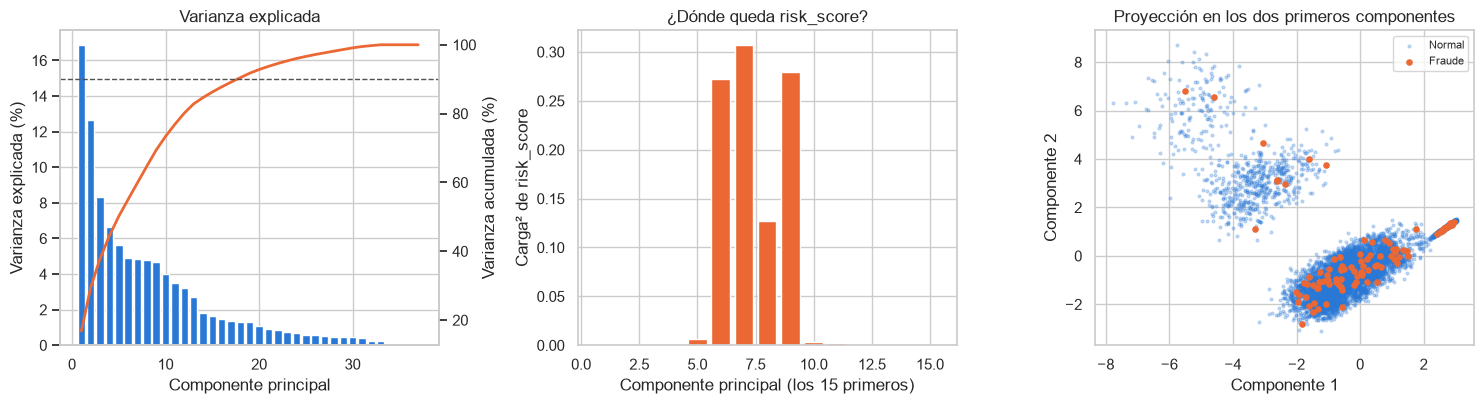

In [11]:
pre_vis = preprocesador().fit(X_train[COLS])
Z_train = pre_vis.transform(X_train[COLS])
pca_vis = PCA(random_state=RANDOM_STATE).fit(Z_train)
var_exp = pca_vis.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
k90 = int(np.searchsorted(var_acum, 0.90) + 1)
idx_risk = list(nombres).index("cont__risk_score")
carga_risk = pca_vis.components_[:, idx_risk] ** 2

print(f"Componentes para explicar el 90 % de la varianza: {k90} de {N_COLUMNAS} ({100 * k90 / N_COLUMNAS:.0f} % de las columnas)")
print(f"Varianza explicada por el primer componente: {100 * var_exp[0]:.1f} % · por los 5 primeros: {100 * var_acum[4]:.1f} %")
print(f"risk_score: carga cuadrática máxima en un componente = {carga_risk.max():.2f} (componente {int(np.argmax(carga_risk)) + 1}); "
      f"componentes que reúnen el 80 % de su varianza: {int(np.searchsorted(np.cumsum(np.sort(carga_risk)[::-1]), 0.8) + 1)}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
ax.bar(range(1, len(var_exp) + 1), 100 * var_exp, color=COLORES[0])
ax2 = ax.twinx()
ax2.plot(range(1, len(var_exp) + 1), 100 * var_acum, color=COLORES[1], lw=2)
ax2.axhline(90, color=COLOR_REF, ls="--", lw=1)
ax2.grid(False)
ax.set_xlabel("Componente principal")
ax.set_ylabel("Varianza explicada (%)")
ax2.set_ylabel("Varianza acumulada (%)")
ax.set_title("Varianza explicada")

ax = axes[1]
ax.bar(range(1, 16), carga_risk[:15], color=COLORES[1])
ax.set_xlabel("Componente principal (los 15 primeros)")
ax.set_ylabel("Carga² de risk_score")
ax.set_title("¿Dónde queda risk_score?")

ax = axes[2]
Zp = pca_vis.transform(Z_train)
ax.scatter(Zp[y_train == 0, 0], Zp[y_train == 0, 1], s=4, alpha=0.25, color=COLORES[0], label="Normal")
ax.scatter(Zp[y_train == 1, 0], Zp[y_train == 1, 1], s=14, color=COLORES[1], label="Fraude")
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.set_title("Proyección en los dos primeros componentes")
ax.legend(fontsize=8)
savefig("fig_pca")
plt.show()

*Figura (PCA). Izquierda: varianza explicada por componente y acumulada (la línea discontinua marca el 90 %). Centro: fracción de la varianza de `risk_score` que aporta a cada uno de los primeros componentes. Derecha: proyección del entrenamiento en los dos primeros componentes.*

Se reajustan los hiperparámetros de los dos modelos en el espacio de componentes principales, eligiendo el número de componentes por validación cruzada.

In [12]:
ajustar_espacio("PCA")
tabla_espacio("PCA")

  PCA · Random Forest balanceado: dimensión 10, validación PR-AUC 0.097, prueba 0.016 (35 s acumulados)
  PCA · Gradient boosting: dimensión 10, validación PR-AUC 0.097, prueba 0.060 (115 s acumulados)


,dimensión,hiperparámetros,PR-AUC entrenamiento,PR-AUC validación [IC 95 %],PR-AUC prueba [IC 95 %],Recall@2 % val. / prueba
modelo,,,,,,
Random Forest balanceado,10,"{'max_features': 0.5, 'min_samples_leaf': 5, '...",0.434,"0.097 [0.049, 0.146]","0.016 [0.011, 0.037]",0.173 / 0.080
Gradient boosting,10,"{'learning_rate': 0.03, 'max_depth': 2, 'n_com...",0.255,"0.097 [0.029, 0.166]","0.060 [0.012, 0.157]",0.173 / 0.080


In [13]:
filas = []
for nombre in MODELOS:
    b = RES[("PCA", nombre)]["busqueda"]
    r = pd.DataFrame(b.cv_results_)
    for k, g in r.groupby("param_red__n_components"):
        filas.append({"modelo": nombre, "componentes": int(k), "PR-AUC validación (mejor configuración del modelo)": g["mean_test_pr_auc"].max()})
curva_pca = pd.DataFrame(filas).pivot(index="componentes", columns="modelo", values="PR-AUC validación (mejor configuración del modelo)")
curva_pca

modelo,Gradient boosting,Random Forest balanceado
componentes,,
2,0.022,0.023
5,0.021,0.025
10,0.097,0.097
20,0.089,0.083
30,0.091,0.069


## 5.4 UMAP (ítem 11 de la guía)

UMAP construye una representación de baja dimensión que conserva la estructura de vecindad local. Se ajusta **dentro de cada partición de entrenamiento** y proyecta la partición de validación con `transform`; ajustarlo con todos los datos antes de validar sería una fuga de información. Se exploran dos versiones:

- **No supervisada:** usa solo las variables. `n_components` ∈ {2, 5, 10}, `n_neighbors` = 30, `min_dist` = 0,1.
- **Supervisada:** usa además la etiqueta del entrenamiento para construir la representación (como lo haría un método supervisado de reducción). La etiqueta nunca se usa para proyectar la validación. `n_components` ∈ {2, 5}.

Se fijan `n_neighbors` y `min_dist` por costo computacional (cada ajuste de UMAP toma del orden de 10 s); es una limitación que se declara y que favorece, si acaso, al espacio completo.

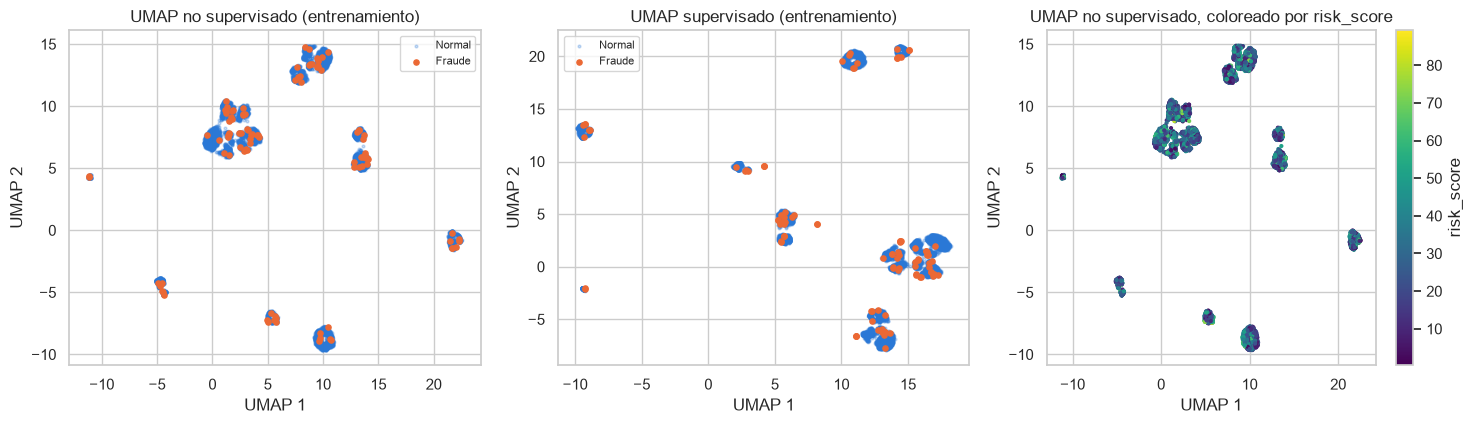

UMAP no supervisado: fracción de los vecinos más cercanos (k = 15) de cada transacción con risk_score ≥ 70 que también tienen risk_score ≥ 70: 0.060 (proporción de transacciones con risk_score ≥ 70 en la muestra: 0.009)


In [14]:
umap_vis = UMAPEmbedding(n_components=2, n_neighbors=N_VECINOS).fit(Z_train)
E = umap_vis.umap_.embedding_
umap_sup_vis = UMAPEmbedding(n_components=2, n_neighbors=N_VECINOS, supervisado=True).fit(Z_train, y_train)
E_sup = umap_sup_vis.umap_.embedding_

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, emb, titulo in [(axes[0], E, "UMAP no supervisado"), (axes[1], E_sup, "UMAP supervisado")]:
    ax.scatter(emb[y_train == 0, 0], emb[y_train == 0, 1], s=4, alpha=0.25, color=COLORES[0], label="Normal")
    ax.scatter(emb[y_train == 1, 0], emb[y_train == 1, 1], s=14, color=COLORES[1], label="Fraude")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title(titulo + " (entrenamiento)")
    ax.legend(fontsize=8)
sc = axes[2].scatter(E[:, 0], E[:, 1], c=X_train["risk_score"], s=4, cmap="viridis")
axes[2].set_xlabel("UMAP 1")
axes[2].set_ylabel("UMAP 2")
axes[2].set_title("UMAP no supervisado, coloreado por risk_score")
plt.colorbar(sc, ax=axes[2], label="risk_score")
savefig("fig_umap")
plt.show()

alto = (X_train["risk_score"] >= 70).to_numpy()
print(f"UMAP no supervisado: fracción de los vecinos más cercanos (k = 15) de cada transacción con risk_score ≥ 70 que también tienen risk_score ≥ 70: ", end="")
from sklearn.neighbors import NearestNeighbors
vecinos = NearestNeighbors(n_neighbors=16).fit(E).kneighbors(E[alto], return_distance=False)[:, 1:]
print(f"{alto[vecinos].mean():.3f} (proporción de transacciones con risk_score ≥ 70 en la muestra: {alto.mean():.3f})")

*Figura (UMAP). Izquierda y centro: proyección bidimensional del entrenamiento sin y con uso de la etiqueta. Derecha: la misma proyección no supervisada coloreada por `risk_score`.*

In [15]:
ajustar_espacio("UMAP")
tabla_espacio("UMAP")

  UMAP · Random Forest balanceado: dimensión 10, validación PR-AUC 0.020, prueba 0.017 (583 s acumulados)
  UMAP · Gradient boosting: dimensión 5, validación PR-AUC 0.027, prueba 0.018 (1026 s acumulados)


,dimensión,hiperparámetros,PR-AUC entrenamiento,PR-AUC validación [IC 95 %],PR-AUC prueba [IC 95 %],Recall@2 % val. / prueba
modelo,,,,,,
Random Forest balanceado,10,"{'max_features': 0.5, 'min_samples_leaf': 20, ...",0.079,"0.020 [-0.003, 0.042]","0.017 [0.012, 0.034]",0.015 / 0.000
Gradient boosting,5,"{'learning_rate': 0.1, 'max_depth': 2, 'n_comp...",0.179,"0.027 [-0.014, 0.068]","0.018 [0.011, 0.059]",0.020 / 0.040


In [16]:
ajustar_espacio("UMAP supervisado")
tabla_espacio("UMAP supervisado")

  UMAP supervisado · Random Forest balanceado: dimensión 5, validación PR-AUC 0.020, prueba 0.018 (337 s acumulados)
  UMAP supervisado · Gradient boosting: dimensión 2, validación PR-AUC 0.018, prueba 0.020 (820 s acumulados)


,dimensión,hiperparámetros,PR-AUC entrenamiento,PR-AUC validación [IC 95 %],PR-AUC prueba [IC 95 %],Recall@2 % val. / prueba
modelo,,,,,,
Random Forest balanceado,5,"{'max_features': 'sqrt', 'min_samples_leaf': 2...",0.144,"0.020 [-0.002, 0.042]","0.018 [0.011, 0.058]",0.020 / 0.040
Gradient boosting,2,"{'learning_rate': 0.1, 'max_depth': 4, 'n_comp...",0.643,"0.018 [0.013, 0.023]","0.020 [0.014, 0.046]",0.015 / 0.040


## 5.5 Comparación de los espacios y tabla final

### Tabla con el porcentaje de reducción (ítems 10 y 11)

Para cada espacio y modelo: dimensión alcanzada, **porcentaje de reducción** respecto a las 37 columnas del espacio completo, hiperparámetros elegidos y desempeño en entrenamiento, validación y prueba con intervalos de confianza. La última columna contrasta la PR-AUC de validación con la del espacio completo (diferencia y p-valor de la prueba t pareada con corrección de Nadeau y Bengio, sobre las mismas particiones).

In [17]:
ESPACIOS = ["Completo", "Selección univariada", "Selección 5.1", "PCA", "UMAP", "UMAP supervisado"]
filas = []
for espacio in ESPACIOS:
    for nombre in MODELOS:
        f = RES[(espacio, nombre)]["fila"]
        lo, hi = f["test_pr_auc_ic"]
        dif, p = prueba_pareada_nb(RES[(espacio, nombre)]["val_pr_auc"], RES[("Completo", nombre)]["val_pr_auc"])
        filas.append({"espacio": espacio, "modelo": nombre, "dimensión": f["dimensión"], "reducción %": f["reducción_%"],
                      "hiperparámetros": f["hiperparámetros"], "PR-AUC entren.": f["train_pr_auc"],
                      "PR-AUC validación [IC 95 %]": fmt_nb(RES[(espacio, nombre)]["val_pr_auc"]),
                      "PR-AUC prueba [IC 95 %]": f"{f['test_pr_auc']:.3f} [{lo:.3f}, {hi:.3f}]",
                      "Recall@2 % val.": f["val_recall_2pct"], "Recall@2 % prueba": f["test_recall_2pct"],
                      "Dif. val. vs completo": dif if espacio != "Completo" else np.nan,
                      "p": p if espacio != "Completo" else np.nan})
tabla_final = pd.DataFrame(filas).set_index(["espacio", "modelo"])
display(tabla_final.style.format({"reducción %": "{:.0f}", "PR-AUC entren.": "{:.3f}", "Recall@2 % val.": "{:.3f}",
                                  "Recall@2 % prueba": "{:.3f}", "Dif. val. vs completo": "{:+.3f}", "p": "{:.3f}"}))

### Referencia: validación cruzada anidada

La PR-AUC de validación es optimista porque la configuración se elige con los mismos datos con que se evalúa (en el notebook 03 la del Random Forest bajó de 0,152 a 0,111 al anidar). Para medir cuánto, se repite la evaluación con **validación cruzada anidada** (validación externa de las mismas particiones que el notebook 03; selección de hiperparámetros en una validación interna de 3 particiones) para el espacio completo y el de selección, y se compara con `risk_score` sin modelo en las mismas particiones. No se anida PCA ni UMAP por costo: su validación está inflada por una selección adicional (el número de componentes), así que anidarlos solo podría empeorarlos.

In [18]:
CV_EXTERNA = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE + 1)
CV_INTERNA = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
R_EXT = 1 / (CV_EXTERNA.cvargs["n_splits"] - 1)

anidada = {}
inicio = time.time()
for espacio in ["Completo", "Selección univariada"]:
    for nombre in MODELOS:
        interna = GridSearchCV(construir(nombre, espacio), {**MALLA_ESPACIO[espacio], **MALLA_MODELO[nombre]},
                               scoring="average_precision", cv=CV_INTERNA, n_jobs=1)
        anidada[(espacio, nombre)] = cross_validate(interna, df[COLS], y, cv=CV_EXTERNA, scoring=METRICAS, n_jobs=N_JOBS)
        print(f"  {espacio} · {nombre}: listo ({time.time() - inicio:.0f} s acumulados)")

ref_rs = {m: np.array([f(y[te], df["risk_score"].to_numpy()[te]) for _, te in CV_EXTERNA.split(df, y)]) for m, f in FUNCIONES.items()}

filas = []
for (espacio, nombre), r in anidada.items():
    filas.append({"espacio": espacio, "modelo": nombre, "PR-AUC anidada [IC 95 %]": "{:.3f} [{:.3f}, {:.3f}]".format(*ic_nb(r["test_pr_auc"], R_EXT)),
                  "Recall@2 % anidada": np.mean(r["test_recall_2pct"]),
                  "PR-AUC de validación (tabla final)": RES[(espacio, nombre)]["fila"]["val_pr_auc"]})
filas.append({"espacio": "—", "modelo": "risk_score sin modelo", "PR-AUC anidada [IC 95 %]": "{:.3f} [{:.3f}, {:.3f}]".format(*ic_nb(ref_rs["pr_auc"], R_EXT)),
              "Recall@2 % anidada": ref_rs["recall_2pct"].mean(), "PR-AUC de validación (tabla final)": np.nan})
pd.DataFrame(filas).set_index(["espacio", "modelo"])

  Completo · Random Forest balanceado: listo (30 s acumulados)
  Completo · Gradient boosting: listo (77 s acumulados)
  Selección univariada · Random Forest balanceado: listo (106 s acumulados)
  Selección univariada · Gradient boosting: listo (120 s acumulados)


PR-AUC anidada [IC 95 %]  Recall@2 % anidada  PR-AUC de validación (tabla final)
espacio              modelo                                                                                                   
Completo             Random Forest balanceado     0.120 [0.028, 0.211]               0.250                               0.150
                     Gradient boosting            0.119 [0.032, 0.207]               0.242                               0.145
Selección univariada Random Forest balanceado     0.084 [0.012, 0.157]               0.214                               0.162
                     Gradient boosting            0.079 [0.015, 0.142]               0.206                               0.146
—                    risk_score sin modelo        0.121 [0.045, 0.197]               0.238                                 NaN

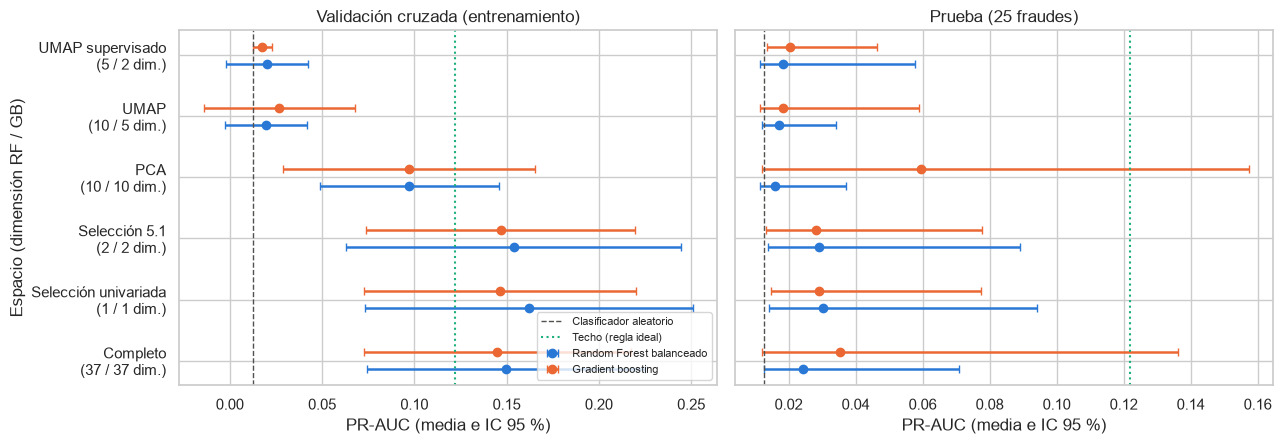

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (titulo, clave) in zip(axes, [("Validación cruzada (entrenamiento)", "val"), ("Prueba (25 fraudes)", "test")]):
    for j, nombre in enumerate(MODELOS):
        for i, espacio in enumerate(ESPACIOS):
            if clave == "val":
                m, lo, hi = ic_nb(RES[(espacio, nombre)]["val_pr_auc"])
            else:
                f = RES[(espacio, nombre)]["fila"]
                m, (lo, hi) = f["test_pr_auc"], f["test_pr_auc_ic"]
            ax.errorbar(m, i + (j - 0.5) * 0.28, xerr=[[m - lo], [hi - m]], fmt="o", ms=6, lw=1.8, capsize=3, color=COLORES[j],
                        label=nombre if i == 0 else None)
    ax.axvline(y.mean(), color=COLOR_REF, ls="--", lw=1, label="Clasificador aleatorio")
    ax.axvline(0.122, color=COLORES[2], ls=":", lw=1.5, label="Techo (regla ideal)")
    ax.set_yticks(range(len(ESPACIOS)), [f"{e}\n({RES[(e, MODELOS[0])]['fila']['dimensión']} / {RES[(e, MODELOS[1])]['fila']['dimensión']} dim.)" for e in ESPACIOS])
    ax.invert_yaxis()
    ax.set_xlabel("PR-AUC (media e IC 95 %)")
    ax.set_title(titulo)
axes[0].set_ylabel("Espacio (dimensión RF / GB)")
axes[0].legend(fontsize=8, loc="lower right")
savefig("fig_reduccion_comparacion")
plt.show()

*Figura (comparación de espacios). PR-AUC de los dos mejores modelos en cada espacio, en validación cruzada (izquierda, intervalo con corrección de Nadeau y Bengio) y en la partición de prueba (derecha, intervalo bootstrap). La línea discontinua es un clasificador aleatorio y la punteada, el techo de la regla ideal calculado en el notebook 04. Los límites inferiores negativos de algunos intervalos son un artefacto de la aproximación normal; la PR-AUC no puede ser negativa.*

## 5.6 Conclusiones

1. **Análisis individual (ítem 9).** De las 22 variables, solo 2 superan el criterio (q < 0,05 con Benjamini–Hochberg; ambas superan también Bonferroni): `risk_score` (AUC 0,633; q < 0,001) y `cambio_categoria` (AUC 0,448; q = 0,017). Se eliminan las otras 20, entre ellas las cuatro categóricas (V de Cramér ≤ 0,027; q ≥ 0,90) y el puntaje `anomalia_historial` (AUC 0,462; q = 0,61). Las más cercanas al umbral son `hour_sin` y `desvio_log_monto` (q = 0,17). La importancia por permutación **confirma la decisión**: en los dos modelos, `risk_score` es la única variable cuya caída de PR-AUC tiene un intervalo que excluye el cero. `cambio_categoria` muestra una asociación inversa débil (el fraude es algo menos frecuente cuando el usuario cambia de categoría), pero los modelos no la usan (importancia nula) y el filtro aplicado dentro de cada partición no la selecciona nunca. Por eso se interpreta como un efecto débil o un falso positivo, no como una señal aprovechable.

2. **Selección de variables.** La selección univariada dentro de la validación conserva **una sola columna, `risk_score`, en las 10 particiones** (97 % de reducción). Su PR-AUC de validación es igual a la del espacio completo: Random Forest balanceado 0,162 frente a 0,150 (+0,013; p = 0,55) y gradient boosting 0,146 frente a 0,145 (+0,001; p = 0,95). Las dos variables del análisis 5.1 (95 % de reducción) dan lo mismo (+0,004 y +0,002; p ≥ 0,87). En prueba, los tres espacios quedan entre 0,024 y 0,035. La validación anidada matiza el resultado: el espacio completo obtiene 0,120 (Random Forest) y 0,119 (gradient boosting), y la selección univariada 0,084 y 0,079, con intervalos que se solapan ampliamente; `risk_score` sin modelo obtiene 0,121. Las dos estimaciones no coinciden en el signo de la diferencia, así que no hay una diferencia demostrable. Una posible explicación de la caída en la anidada es que, con una sola variable, la búsqueda elige configuraciones menos regularizadas (por ejemplo, tasa 0,1 y profundidad 4 en el gradient boosting), que fragmentan `risk_score` en intervalos finos. *Nota:* el Random Forest del espacio completo obtiene aquí 0,120 en la anidada frente a 0,111 en el notebook 03; la diferencia se debe a la malla (200 árboles y sin `min_samples_leaf` = 1).

3. **PCA (ítem 10).** Ambos modelos eligen **10 componentes (73 % de reducción)**, mientras que la regla del 90 % de la varianza exigiría 18 de 37. El desempeño **cae**: PR-AUC de validación 0,097 en los dos modelos, frente a 0,150 y 0,145 en el espacio completo (−0,052 y −0,048; p = 0,13 y 0,21; en prueba 0,016 y 0,060). La causa se ve en la figura: PCA no usa la etiqueta y maximiza la varianza de las 37 columnas estandarizadas, así que `risk_score`, una de ellas, queda repartida entre varios componentes (su carga cuadrática máxima es 0,31, en el componente 7, y necesita 3 componentes para reunir el 80 % de su varianza). Con 2 o 5 componentes la PR-AUC es ≈ 0,02 (azar), porque esos componentes no contienen `risk_score`; salta a 0,097 cuando entran los componentes 6 a 9. Los grupos de la proyección en los dos primeros componentes reflejan las categóricas, no el fraude.

4. **UMAP (ítem 11).** La versión no supervisada elige 10 dimensiones con el Random Forest (73 % de reducción) y 5 con el gradient boosting (86 %), y **destruye la señal**: PR-AUC de validación 0,020 y 0,027 (−0,130 y −0,118 respecto al completo; p = 0,004 y 0,003), con un recall@2 % de 0,015 y 0,020, igual al azar. La vecindad de UMAP la determinan las categóricas: solo el 6 % de los vecinos de una transacción con `risk_score` ≥ 70 tienen también `risk_score` alto. La versión supervisada (5 dimensiones con el Random Forest y 2 con el gradient boosting; 86 % y 95 % de reducción) **no lo corrige**: 0,020 y 0,018 en validación (p = 0,006 y 0,003). Además, muestra un sobreajuste claro: el gradient boosting alcanza 0,643 en entrenamiento frente a 0,018 en validación, porque la separación por etiqueta que UMAP construye en el entrenamiento no se traslada a la validación con `transform`.

5. **Respuesta a la guía.** Sí es posible reducir la complejidad del modelo sin una pérdida demostrable de desempeño, pero **por selección y no por extracción**. Un modelo con solo `risk_score` (97 % de reducción) iguala en validación al espacio de 37 columnas; la anidada sugiere una pérdida moderada que no es concluyente. PCA y UMAP no son recomendables en este problema: como no usan la etiqueta (o, en UMAP supervisado, la sobreajustan), mezclan la única variable informativa con 36 que no tienen señal. El espacio recomendado es la **selección (`risk_score`)**, por parsimonia. Esto es coherente con las secciones 2 y 4: todo el desempeño útil viene de `risk_score`, y los modelos, con cualquier número de variables, no superan a `risk_score` usado directamente como puntaje (PR-AUC anidada 0,121) ni al techo de ≈ 0,12.